In [20]:
from transformers import Qwen2_5_VLForConditionalGeneration, AutoTokenizer, AutoProcessor
from qwen_vl_utils import process_vision_info
import os, json, torch, gc

In [21]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Device:", device)

Device: mps


In [22]:
processor = AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-3B-Instruct")
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen2.5-VL-3B-Instruct", torch_dtype="auto", device_map="auto"
)

Loading weights: 100%|██████████| 824/824 [00:11<00:00, 73.81it/s] 


In [ ]:
IMG_DIR = "/Users/administrator/Documents/SpottySearch/Data"
CACHE = "captions.json"

MAX_PIXELS = 1024 * 1024 

image_files = [f for f in os.listdir('Data') if f.lower().endswith('.jpg')]
image_files.sort()

In [24]:
captions = {}
if os.path.exists(CACHE):
    with open(CACHE) as f:
        captions = json.load(f)

In [25]:
PROMPT = (
    "List every distinct pottery item in this image. For each, give its colour, "
    "form (mug, plate, bowl, figurine, etc.) and any patterns or designs, "
    "one short sentence per item."
)

In [26]:
def caption_image(path):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": path, "max_pixels": MAX_PIXELS},
            {"type": "text", "text": PROMPT},
        ],
    }]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text], images=image_inputs, videos=video_inputs,
        padding=True, return_tensors="pt",
    ).to("mps")
    with torch.no_grad():
        generated_ids = model.generate(**inputs, max_new_tokens=256, do_sample=False)
    trimmed = [out[len(inp):] for inp, out in zip(inputs.input_ids, generated_ids)]
    cap = processor.batch_decode(
        trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0].strip()
    del inputs, generated_ids, trimmed, image_inputs
    gc.collect()
    torch.mps.empty_cache()
    return cap

In [27]:
for i, file in enumerate(image_files):
    if file in captions:                   # skip what's already done
        continue
    captions[file] = caption_image(os.path.join(IMG_DIR, file))
    with open(CACHE, "w") as f:            # save after each one
        json.dump(captions, f, indent=2)
    print(f"[{i+1}/{len(image_files)}] {file}: {captions[file][:80]}")

[1/43] PHOTO-2026-06-02-06-58-12 10.jpg: 1. **Plate**: White with floral designs, including yellow flowers and green leav
[2/43] PHOTO-2026-06-02-06-58-12 11.jpg: 1. **Plate**: Light green with a checkered pattern of pink and white squares.
2.
[3/43] PHOTO-2026-06-02-06-58-12 12.jpg: 1. **Figurine**: Blue and green, shaped like a rabbit with a pointed hat.
2. **P
[4/43] PHOTO-2026-06-02-06-58-12 13.jpg: 1. **Plate**: Pink with small pink hearts arranged in vertical lines.
2. **Figur
[5/43] PHOTO-2026-06-02-06-58-12 14.jpg: 1. Mug: White with black spade shapes.
2. Mug: White with pink hearts.
3. Mug: W
[6/43] PHOTO-2026-06-02-06-58-12 15.jpg: 1. **Plate**: Light blue with a large white daisy in the center and smaller dais
[7/43] PHOTO-2026-06-02-06-58-12 16.jpg: 1. **Plate**: Pink with a black spider web design.
2. **Mug**: White with "I lov
[8/43] PHOTO-2026-06-02-06-58-12 17.jpg: 1. Mug: Light brown with a blue handle and face design.
2. Plate: Pink with blac
[9/43] PHOTO-2026-06-02-

In [29]:
import matplotlib.pyplot as plt
from PIL import Image
import os, textwrap

In [32]:
def show_pot(file, caption=None, wrap=46):
    caption = (captions[file] if caption is None else caption).replace("**", "").strip()
    img = Image.open(os.path.join(IMG_DIR, file))
    wrapped = "\n".join(textwrap.fill(l, wrap) for l in caption.splitlines() if l.strip())
    n = wrapped.count("\n") + 1

    fig, (ax_img, ax_txt) = plt.subplots(
        2, 1, figsize=(5, 5 + 0.22 * n),
        gridspec_kw={"height_ratios": [5, 0.22 * n]},
        constrained_layout=True,
    )
    ax_img.imshow(img); ax_img.axis("off")
    ax_img.set_title(file, fontsize=8, color="grey")
    ax_txt.axis("off")
    ax_txt.text(0.5, 1.0, wrapped, ha="center", va="top", fontsize=9)
    plt.show()

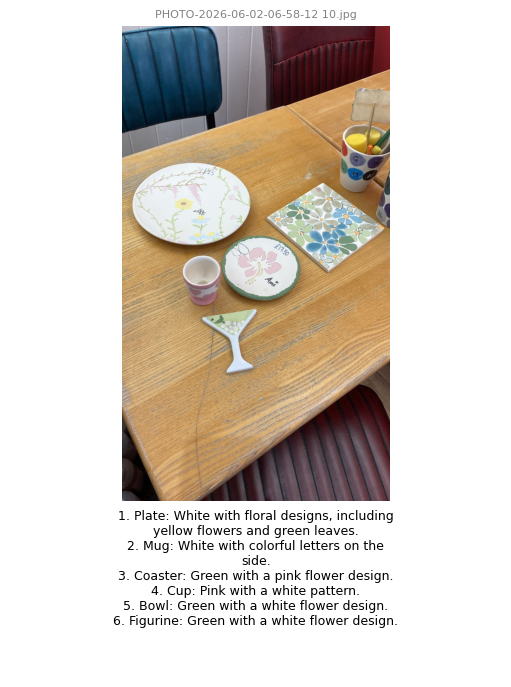

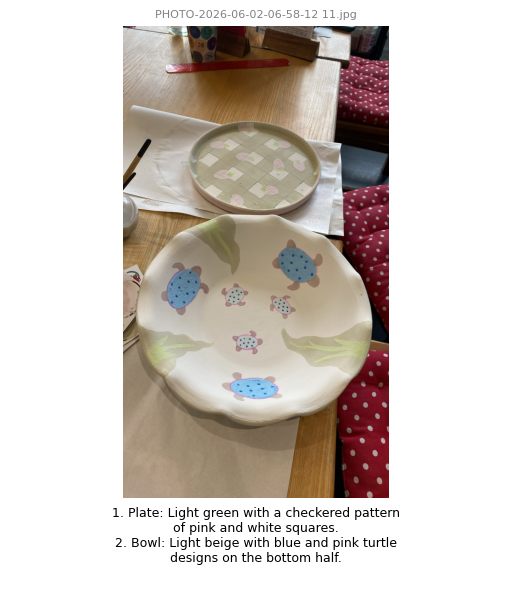

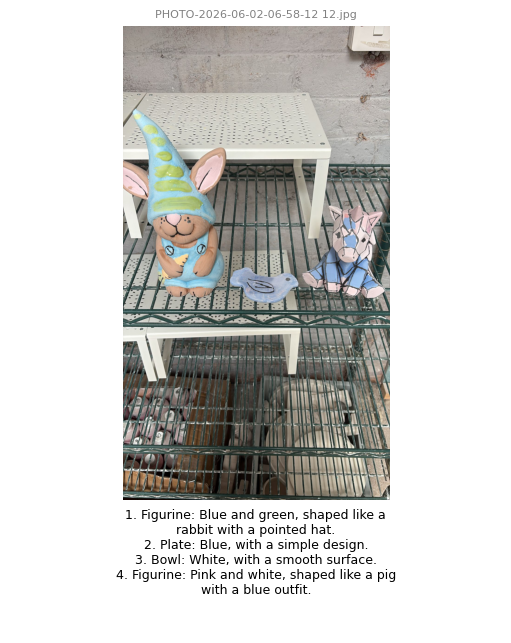

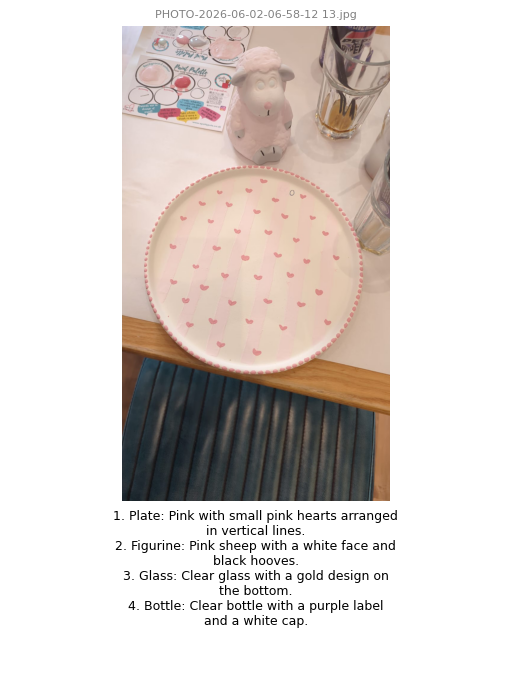

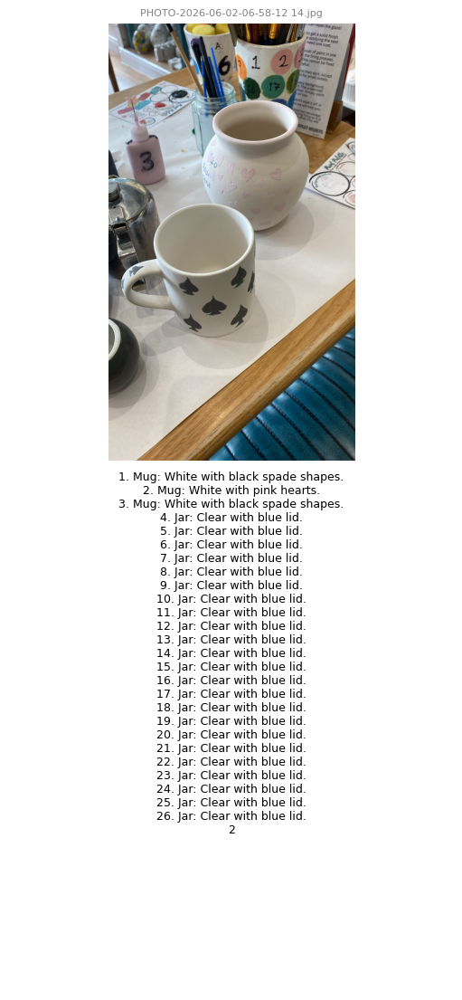

...

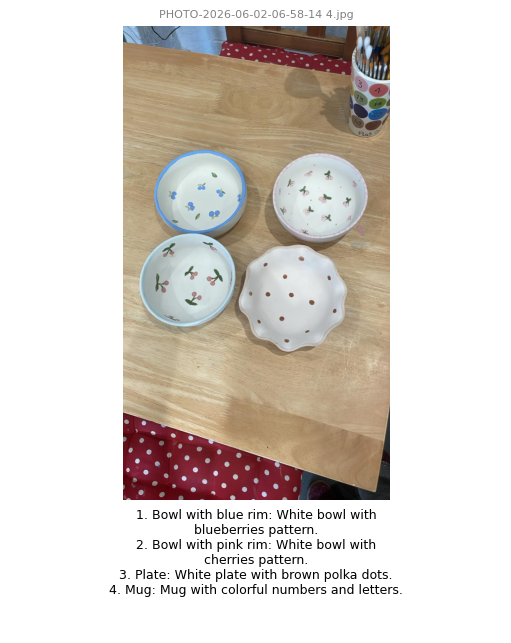

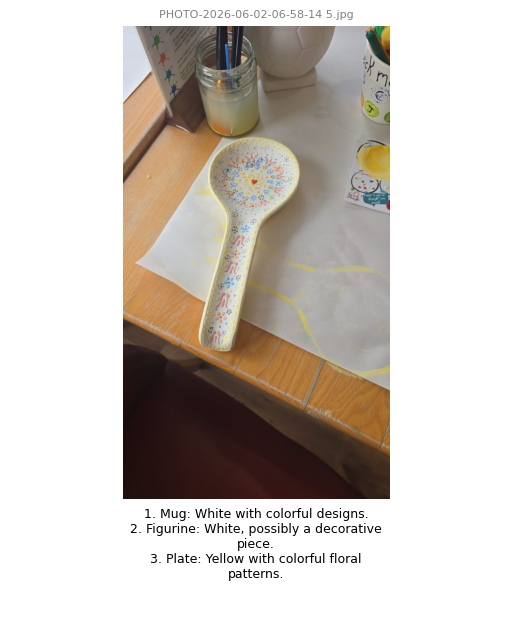

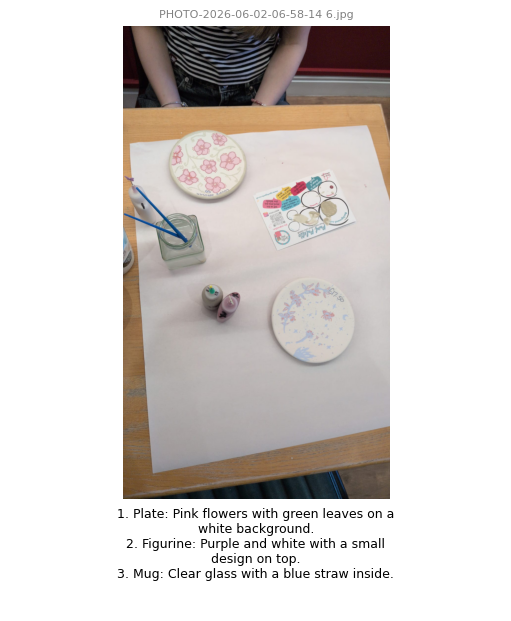

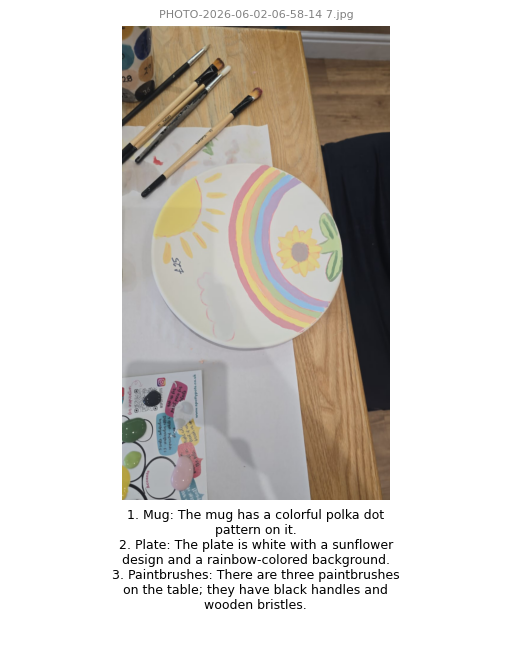

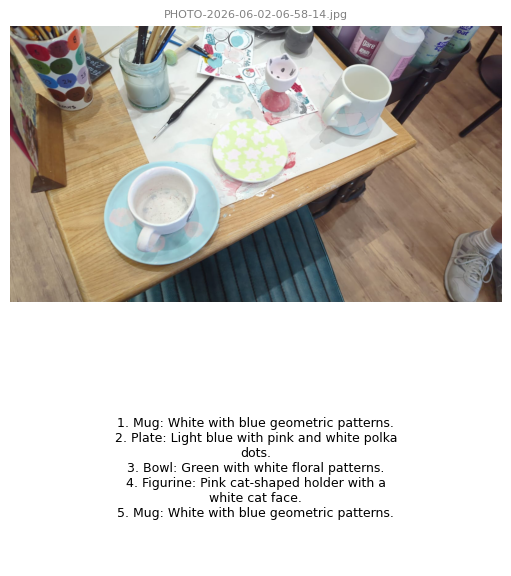

In [33]:
for file in image_files:
    show_pot(file)

In [38]:
from sentence_transformers import SentenceTransformer
import numpy as np

In [39]:
text_model = SentenceTransformer("all-MiniLM-L6-v2")
caption_list = [captions[f] for f in image_files]
caption_vectors = text_model.encode(caption_list, normalize_embeddings=True)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16517.43it/s]


In [40]:
def search_captions(query, k=3):
    q = text_model.encode(query, normalize_embeddings=True)
    sims = caption_vectors @ q
    top = np.argsort(sims)[::-1][:k]
    for i in top:
        print(f"score {sims[i]:.3f}")
        show_pot(image_files[i])
    return top

score 0.647


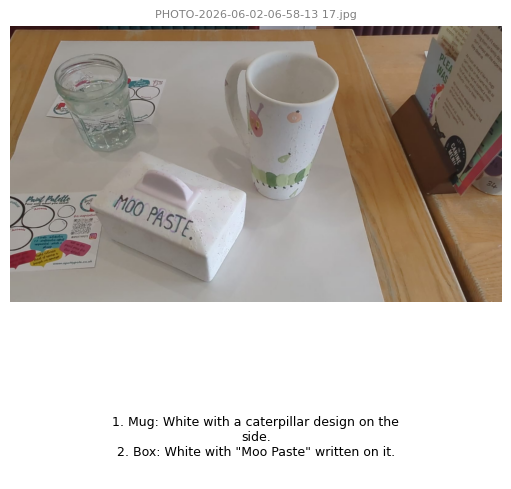

score 0.495


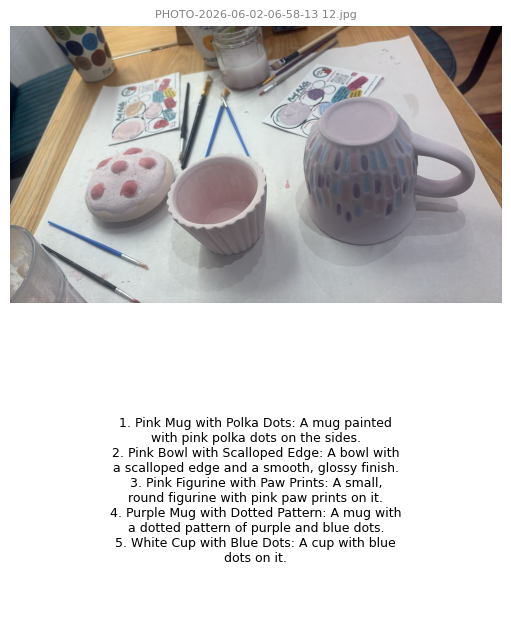

score 0.491


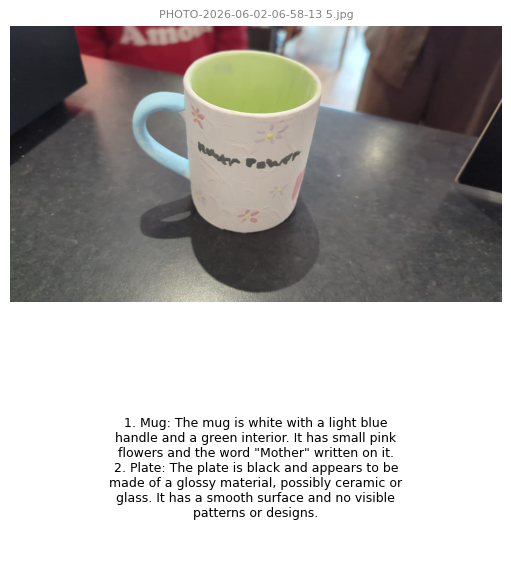

array([26, 21, 30])

In [41]:
search_captions("a mug with a caterpillar on it")

score 0.458


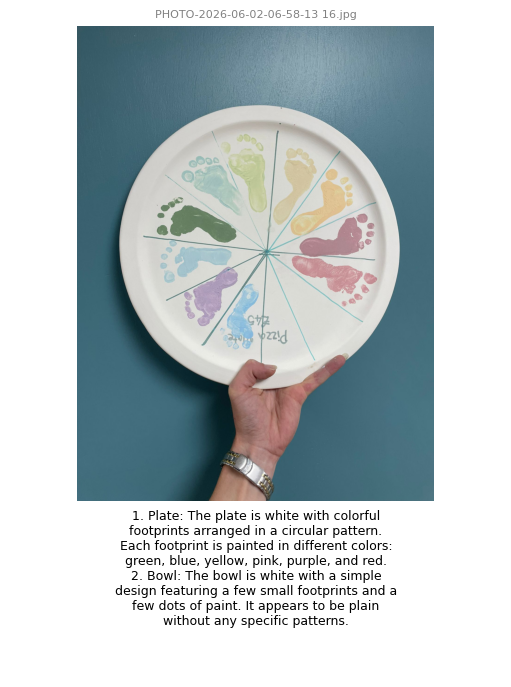

score 0.415


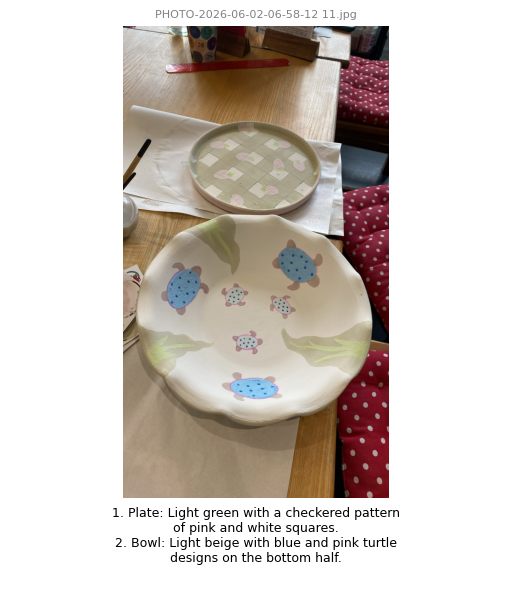

score 0.389


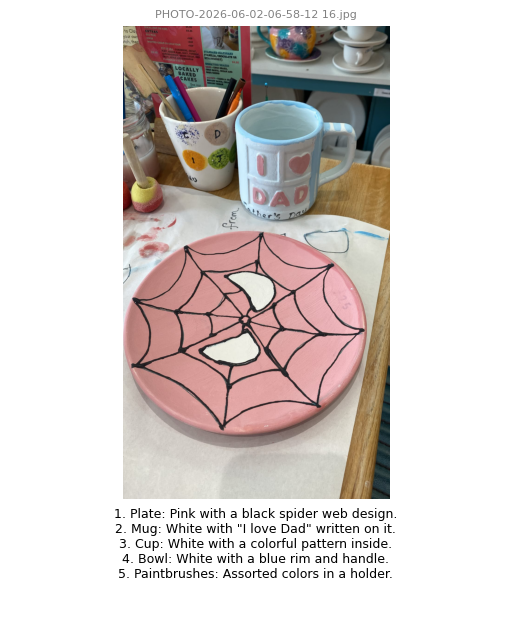

array([25,  1,  6])

In [43]:
search_captions("plate with red spider man design")